<a href="https://colab.research.google.com/github/Supan-Roy/financial-scam-analysis/blob/main/notebooks/09_external_source_generalization_evaluation.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [9]:
# ============================================================
# Notebook 09: External-Source Generalization Evaluation
# Cell 1: Mount Google Drive & Verify Required Files
# ============================================================

from google.colab import drive
from pathlib import Path

# Mount Google Drive
drive.mount('/content/drive')

# Project paths
PROJECT_DIR = Path("/content/drive/MyDrive/financial-scam-analysis")

MODEL_DIR = PROJECT_DIR / "models" / "distilbert_binary"

EVAL_DIR = PROJECT_DIR / "data" / "external_evaluation"

# Required evaluation datasets
EVAL_FILES = {
    "external_scams": EVAL_DIR / "external_fin_scam_curated.csv",
    "primary_test": EVAL_DIR / "expanded_binary_external_test.csv",
    "balanced_test": EVAL_DIR / "balanced_binary_external_test.csv",
}

# Verify model directory
print("\n" + "=" * 60)
print("MODEL DIRECTORY")
print("=" * 60)

if MODEL_DIR.exists():
    print(f"Found: {MODEL_DIR}")

    for file in sorted(MODEL_DIR.iterdir()):
        if file.is_file():
            print(f"  ✓ {file.name}")
else:
    raise FileNotFoundError(f"Model directory not found: {MODEL_DIR}")

# Verify evaluation datasets
print("\n" + "=" * 60)
print("EVALUATION DATASETS")
print("=" * 60)

for name, path in EVAL_FILES.items():
    if path.exists():
        print(f"✓ {name}: {path.name} ({path.stat().st_size / (1024**2):.2f} MB)")
    else:
        raise FileNotFoundError(f"Missing dataset: {path}")

print("\nAll required paths verified.")

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).

MODEL DIRECTORY
Found: /content/drive/MyDrive/financial-scam-analysis/models/distilbert_binary
  ✓ config.json
  ✓ model.safetensors
  ✓ tokenizer.json
  ✓ tokenizer_config.json
  ✓ training_args.bin

EVALUATION DATASETS
✓ external_scams: external_fin_scam_curated.csv (2.81 MB)
✓ primary_test: expanded_binary_external_test.csv (24.21 MB)
✓ balanced_test: balanced_binary_external_test.csv (5.34 MB)

All required paths verified.


In [10]:
# ============================================================
# Cell 2: Install & Import Dependencies
# ============================================================

%pip install -q transformers datasets accelerate scikit-learn

import os
import gc
import json
import random
import numpy as np
import pandas as pd
import torch

from pathlib import Path
from transformers import (
    AutoTokenizer,
    AutoModelForSequenceClassification,
    DataCollatorWithPadding
)

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix,
    balanced_accuracy_score,
    average_precision_score,
    roc_auc_score
)

# Reproducibility
SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

# Device configuration
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")

print("PyTorch version:", torch.__version__)
print("CUDA available:", torch.cuda.is_available())
print("Device:", DEVICE)

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))

print("\nDependencies imported successfully.")

PyTorch version: 2.14.1+cu130
CUDA available: True
Device: cuda
GPU: Tesla T4

Dependencies imported successfully.


In [11]:
# ============================================================
# Cell 3: Load Original DistilBERT Model & Tokenizer
# ============================================================

print("Loading original Notebook06 model...")

tokenizer = AutoTokenizer.from_pretrained(str(MODEL_DIR))

model = AutoModelForSequenceClassification.from_pretrained(
    str(MODEL_DIR)
)

model.to(DEVICE)
model.eval()

# Inspect model configuration
print("\n" + "=" * 60)
print("MODEL CONFIGURATION")
print("=" * 60)

print("Model path:", MODEL_DIR)
print("Architecture:", model.config.model_type)
print("Base model:", model.config._name_or_path)
print("Number of labels:", model.config.num_labels)
print("Label mapping:", model.config.id2label)
print("Maximum positional embeddings:", model.config.max_position_embeddings)
print("Tokenizer:", tokenizer.__class__.__name__)
print("Tokenizer vocabulary size:", tokenizer.vocab_size)

print("\nModel device:", next(model.parameters()).device)
print("Model loaded successfully.")

Loading original Notebook06 model...


Loading weights:   0%|          | 0/104 [00:00<?, ?it/s]


MODEL CONFIGURATION
Model path: /content/drive/MyDrive/financial-scam-analysis/models/distilbert_binary
Architecture: distilbert
Base model: /content/drive/MyDrive/financial-scam-analysis/models/distilbert_binary
Number of labels: 2
Label mapping: {0: 'LEGITIMATE', 1: 'SCAM'}
Maximum positional embeddings: 512
Tokenizer: BertTokenizer
Tokenizer vocabulary size: 30522

Model device: cuda:0
Model loaded successfully.


In [12]:
# ============================================================
# Cell 4: Load & Inspect Evaluation Datasets
# ============================================================

external_scams = pd.read_csv(EVAL_FILES["external_scams"])
primary_test = pd.read_csv(EVAL_FILES["primary_test"])
balanced_test = pd.read_csv(EVAL_FILES["balanced_test"])

datasets = {
    "External Scams": external_scams,
    "Primary Test": primary_test,
    "Balanced Test": balanced_test
}

for name, df in datasets.items():
    print("\n" + "=" * 65)
    print(name.upper())
    print("=" * 65)

    print("Shape:", df.shape)
    print("\nColumns:")
    print(df.columns.tolist())

    print("\nLabel distribution:")
    print(df["label"].value_counts().sort_index())

    print("\nClass proportions:")
    print(
        df["label"].value_counts(normalize=True)
        .sort_index()
        .round(4)
    )

    print("\nChannel distribution:")
    print(df["channel"].value_counts(dropna=False))

    print("\nFirst record:")
    print(df.iloc[0][["record_id", "label", "channel", "source"]])


EXTERNAL SCAMS
Shape: (792, 35)

Columns:
['record_id', 'original_text', 'normalized_text', 'label', 'channel', 'original_channel', 'is_email_gateway', 'has_gateway_headers', 'source', 'source_url', 'source_license', 'source_record_id', 'is_synthetic', 'scam_subtype', 'fraudulent_intent', 'social_engineering_tactics', 'legitimate_category', 'email_subject', 'email_body', 'duplicate_cluster_id', 'char_count_original', 'word_count_original', 'char_count_normalized', 'word_count_normalized', 'placeholder_count_original', 'placeholder_count_normalized', 'generation_scenario', 'risk_or_safety_note', 'language', 'communication_type', 'group_id', 'split', 'evaluation_origin', 'financial_relevance', 'annotation_status']

Label distribution:
label
1    792
Name: count, dtype: int64

Class proportions:
label
1    1.0
Name: proportion, dtype: float64

Channel distribution:
channel
email    522
sms      270
Name: count, dtype: int64

First record:
record_id                  EXT-SCAM-00001
label  

In [13]:
# ============================================================
# Cell 5: Evaluation Dataset Integrity Validation
# ============================================================

def validate_dataset(name, df):
    print(f"\n--- {name} ---")

    checks = {
        "Unique record IDs": df["record_id"].is_unique,
        "No missing record IDs": df["record_id"].notna().all(),
        "No missing normalized text": df["normalized_text"].notna().all(),
        "No empty normalized text": df["normalized_text"].astype(str).str.strip().ne("").all(),
        "Valid binary labels": set(df["label"].unique()).issubset({0, 1}),
    }

    for check, passed in checks.items():
        print(f"{'PASS' if passed else 'FAIL'}: {check}")

    return all(checks.values())


# Basic integrity checks
integrity_results = {
    "External Scams": validate_dataset("External Scams", external_scams),
    "Primary Test": validate_dataset("Primary Test", primary_test),
    "Balanced Test": validate_dataset("Balanced Test", balanced_test),
}

# Verify all external scam IDs are present in combined datasets
external_ids = set(external_scams["record_id"])

primary_scam_ids = set(
    primary_test.loc[primary_test["label"] == 1, "record_id"]
)

balanced_scam_ids = set(
    balanced_test.loc[balanced_test["label"] == 1, "record_id"]
)

print("\n--- External Scam Inclusion ---")

print("Primary contains all external scams:", external_ids == primary_scam_ids)
print("Balanced contains all external scams:", external_ids == balanced_scam_ids)

assert all(integrity_results.values()), "Dataset integrity check failed."
assert external_ids == primary_scam_ids
assert external_ids == balanced_scam_ids

print("\nAll integrity checks passed.")


--- External Scams ---
PASS: Unique record IDs
PASS: No missing record IDs
PASS: No missing normalized text
PASS: No empty normalized text
PASS: Valid binary labels

--- Primary Test ---
PASS: Unique record IDs
PASS: No missing record IDs
PASS: No missing normalized text
PASS: No empty normalized text
PASS: Valid binary labels

--- Balanced Test ---
PASS: Unique record IDs
PASS: No missing record IDs
PASS: No missing normalized text
PASS: No empty normalized text
PASS: Valid binary labels

--- External Scam Inclusion ---
Primary contains all external scams: True
Balanced contains all external scams: True

All integrity checks passed.


In [14]:
# ============================================================
# Cell 6: Inspect Input Lengths & Confirm Inference Settings
# ============================================================

MAX_LENGTH = 512
BATCH_SIZE = 32
SCAM_LABEL = 1
LEGITIMATE_LABEL = 0
THRESHOLD = 0.5

print("=" * 65)
print("INFERENCE CONFIGURATION")
print("=" * 65)

print("Input column:", "normalized_text")
print("Maximum sequence length:", MAX_LENGTH)
print("Batch size:", BATCH_SIZE)
print("Scam label:", SCAM_LABEL)
print("Legitimate label:", LEGITIMATE_LABEL)
print("Decision threshold:", THRESHOLD)

# Inspect normalized text lengths in tokens
def inspect_token_lengths(name, df):
    sample = df["normalized_text"].astype(str).tolist()

    token_lengths = [
        len(tokenizer.encode(text, add_special_tokens=True, truncation=False))
        for text in sample
    ]

    lengths = pd.Series(token_lengths)

    print(f"\n{name}")
    print("-" * 45)
    print("Records:", len(lengths))
    print("Mean tokens:", round(lengths.mean(), 2))
    print("Median tokens:", int(lengths.median()))
    print("95th percentile:", int(lengths.quantile(0.95)))
    print("Maximum tokens:", int(lengths.max()))
    print("Records exceeding 512:", int((lengths > MAX_LENGTH).sum()))
    print("Percentage exceeding 512:", round((lengths > MAX_LENGTH).mean() * 100, 2), "%")


inspect_token_lengths("External Scams", external_scams)
inspect_token_lengths("Primary Test", primary_test)
inspect_token_lengths("Balanced Test", balanced_test)

print("\nInput inspection completed.")

[transformers] Token indices sequence length is longer than the specified maximum sequence length for this model (804 > 512). Running this sequence through the model will result in indexing errors


INFERENCE CONFIGURATION
Input column: normalized_text
Maximum sequence length: 512
Batch size: 32
Scam label: 1
Legitimate label: 0
Decision threshold: 0.5

External Scams
---------------------------------------------
Records: 792
Mean tokens: 265.62
Median tokens: 137
95th percentile: 1122
Maximum tokens: 5919
Records exceeding 512: 98
Percentage exceeding 512: 12.37 %

Primary Test
---------------------------------------------
Records: 7025
Mean tokens: 294.88
Median tokens: 206
95th percentile: 905
Maximum tokens: 5919
Records exceeding 512: 1182
Percentage exceeding 512: 16.83 %

Balanced Test
---------------------------------------------
Records: 1584
Mean tokens: 271.74
Median tokens: 169
95th percentile: 917
Maximum tokens: 5919
Records exceeding 512: 207
Percentage exceeding 512: 13.07 %

Input inspection completed.


In [15]:
# ============================================================
# Cell 7: Investigate Extremely Long Records
# ============================================================

def inspect_extreme_records(name, df, top_n=10):
    token_lengths = [
        len(tokenizer.encode(text, add_special_tokens=True, truncation=False))
        for text in df["normalized_text"].astype(str)
    ]

    temp = df[[
        "record_id", "label", "channel", "source",
        "char_count_normalized", "word_count_normalized"
    ]].copy()

    temp["actual_token_count"] = token_lengths

    print(f"\n{'=' * 65}")
    print(f"{name.upper()} — LONGEST RECORDS")
    print("=" * 65)

    display(
        temp.nlargest(top_n, "actual_token_count").reset_index(drop=True)
    )

    print("\nRecords exceeding 10,000 tokens:",
          int((temp["actual_token_count"] > 10000).sum()))

    print("Records exceeding 100,000 tokens:",
          int((temp["actual_token_count"] > 100000).sum()))


inspect_extreme_records("External Scams", external_scams)
inspect_extreme_records("Primary Test", primary_test)


EXTERNAL SCAMS — LONGEST RECORDS


,record_id,label,channel,source,char_count_normalized,word_count_normalized,actual_token_count
0,EXT-SCAM-00448,1,email,Jose Nazario Phishing Corpus,7357,1056,5919
1,EXT-SCAM-00348,1,email,Jose Nazario Phishing Corpus,16078,2575,3423
2,EXT-SCAM-00341,1,email,Jose Nazario Phishing Corpus,16056,2576,3402
3,EXT-SCAM-00440,1,email,Jose Nazario Phishing Corpus,3592,176,2936
4,EXT-SCAM-00502,1,email,Jose Nazario Phishing Corpus,9615,1530,2425
5,EXT-SCAM-00478,1,email,Jose Nazario Phishing Corpus,4467,269,2257
6,EXT-SCAM-00433,1,email,Jose Nazario Phishing Corpus,9599,1559,2022
7,EXT-SCAM-00298,1,email,Jose Nazario Phishing Corpus,9019,1435,2015
8,EXT-SCAM-00459,1,email,Jose Nazario Phishing Corpus,4827,514,1946
9,EXT-SCAM-00259,1,email,Jose Nazario Phishing Corpus,8019,1268,1824



Records exceeding 10,000 tokens: 0
Records exceeding 100,000 tokens: 0

PRIMARY TEST — LONGEST RECORDS


,record_id,label,channel,source,char_count_normalized,word_count_normalized,actual_token_count
0,EXT-SCAM-00448,1,email,Jose Nazario Phishing Corpus,7357,1056,5919
1,EXT-SCAM-00348,1,email,Jose Nazario Phishing Corpus,16078,2575,3423
2,EXT-SCAM-00341,1,email,Jose Nazario Phishing Corpus,16056,2576,3402
3,EXT-SCAM-00440,1,email,Jose Nazario Phishing Corpus,3592,176,2936
4,MEAJOR-LEG-035379,0,email,MeAJOR (trec6),6214,652,2549
5,MEAJOR-LEG-055175,0,email,MeAJOR (trec7),7565,457,2507
6,EXT-SCAM-00502,1,email,Jose Nazario Phishing Corpus,9615,1530,2425
7,EXT-SCAM-00478,1,email,Jose Nazario Phishing Corpus,4467,269,2257
8,MEAJOR-LEG-055583,0,email,MeAJOR (trec7),5396,623,2138
9,MEAJOR-LEG-040352,0,email,MeAJOR (trec7),4559,562,2085



Records exceeding 10,000 tokens: 0
Records exceeding 100,000 tokens: 0


In [17]:
# ============================================================
# CELL 8: EXTERNAL DATASET COMPOSITION
# ============================================================

print("=" * 70)
print("EXTERNAL SCAM SOURCE DISTRIBUTION")
print("=" * 70)

print(external_scams["source"].value_counts().to_string())

print("\n" + "=" * 70)
print("EXTERNAL SCAM CHANNEL DISTRIBUTION")
print("=" * 70)

print(external_scams["channel"].value_counts().to_string())

print("\n" + "=" * 70)
print("PRIMARY TEST — CLASS DISTRIBUTION")
print("=" * 70)

print(primary_test["label"].value_counts().sort_index().rename(
    index={0: "LEGITIMATE", 1: "SCAM"}
).to_string())

print("\n" + "=" * 70)
print("PRIMARY TEST — CLASS × CHANNEL")
print("=" * 70)

print(pd.crosstab(
    primary_test["channel"],
    primary_test["label"].map({0: "LEGITIMATE", 1: "SCAM"})
).to_string())

print("\n" + "=" * 70)
print("BALANCED TEST — CLASS DISTRIBUTION")
print("=" * 70)

print(balanced_test["label"].value_counts().sort_index().rename(
    index={0: "LEGITIMATE", 1: "SCAM"}
).to_string())

EXTERNAL SCAM SOURCE DISTRIBUTION
source
Jose Nazario Phishing Corpus          522
Mishra & Soni SMS Phishing Dataset    268
AbayomiAlli SMS Dataset                 2

EXTERNAL SCAM CHANNEL DISTRIBUTION
channel
email    522
sms      270

PRIMARY TEST — CLASS DISTRIBUTION
label
LEGITIMATE    6233
SCAM           792

PRIMARY TEST — CLASS × CHANNEL
label    LEGITIMATE  SCAM
channel                  
email          5766   522
sms             467   270

BALANCED TEST — CLASS DISTRIBUTION
label
LEGITIMATE    792
SCAM          792


In [18]:
# ============================================================
# CELL 9: FINAL PRE-INFERENCE VALIDATION
# ============================================================

EXPECTED_COUNTS = {
    "external_scams": 792,
    "primary_test": 7025,
    "balanced_test": 1584
}

evaluation_datasets = {
    "external_scams": external_scams,
    "primary_test": primary_test,
    "balanced_test": balanced_test
}

print("=" * 70)
print("FINAL PRE-INFERENCE VALIDATION")
print("=" * 70)

for name, df in evaluation_datasets.items():
    print(f"\n{name.upper()}")
    print("-" * 50)

    checks = {
        "Expected record count": len(df) == EXPECTED_COUNTS[name],
        "No duplicate record IDs": df["record_id"].is_unique,
        "No missing normalized text": df["normalized_text"].notna().all(),
        "No empty normalized text": df["normalized_text"].astype(str).str.strip().ne("").all(),
        "Binary labels only": set(df["label"].unique()).issubset({0, 1}),
        "No missing source": df["source"].notna().all(),
        "No missing channel": df["channel"].notna().all()
    }

    for check, passed in checks.items():
        print(f"{'PASS' if passed else 'FAIL'} | {check}")

    assert all(checks.values()), f"Validation failed for {name}"

# Verify external scam IDs are present in both evaluation sets
external_ids = set(external_scams["record_id"])
primary_ids = set(primary_test["record_id"])
balanced_ids = set(balanced_test["record_id"])

assert external_ids.issubset(primary_ids)
assert external_ids.issubset(balanced_ids)

print("\nPASS | All external scam IDs exist in both evaluation sets.")
print("\nAll pre-inference checks passed.")

FINAL PRE-INFERENCE VALIDATION

EXTERNAL_SCAMS
--------------------------------------------------
PASS | Expected record count
PASS | No duplicate record IDs
PASS | No missing normalized text
PASS | No empty normalized text
PASS | Binary labels only
PASS | No missing source
PASS | No missing channel

PRIMARY_TEST
--------------------------------------------------
PASS | Expected record count
PASS | No duplicate record IDs
PASS | No missing normalized text
PASS | No empty normalized text
PASS | Binary labels only
PASS | No missing source
PASS | No missing channel

BALANCED_TEST
--------------------------------------------------
PASS | Expected record count
PASS | No duplicate record IDs
PASS | No missing normalized text
PASS | No empty normalized text
PASS | Binary labels only
PASS | No missing source
PASS | No missing channel

PASS | All external scam IDs exist in both evaluation sets.

All pre-inference checks passed.


In [19]:
# ============================================================
# CELL 10: DEFINE INFERENCE FUNCTION
# ============================================================

from torch.utils.data import Dataset, DataLoader
from tqdm.auto import tqdm

class EvaluationDataset(Dataset):
    def __init__(self, texts):
        self.texts = texts

    def __len__(self):
        return len(self.texts)

    def __getitem__(self, idx):
        return self.texts[idx]


def run_inference(df, dataset_name, batch_size=BATCH_SIZE):
    texts = df["normalized_text"].astype(str).tolist()
    dataset = EvaluationDataset(texts)

    def collate_fn(batch):
        return tokenizer(
            batch,
            max_length=MAX_LENGTH,
            truncation=True,
            padding=True,
            return_tensors="pt"
        )

    loader = DataLoader(
        dataset,
        batch_size=batch_size,
        shuffle=False,
        collate_fn=collate_fn
    )

    all_probabilities = []
    all_predictions = []

    model.eval()

    with torch.inference_mode():
        for batch in tqdm(loader, desc=f"Inferencing {dataset_name}"):
            batch = {k: v.to(DEVICE) for k, v in batch.items()}

            logits = model(**batch).logits
            probabilities = torch.softmax(logits, dim=1)

            scam_probabilities = probabilities[:, SCAM_LABEL]
            predictions = (scam_probabilities >= THRESHOLD).long()

            all_probabilities.extend(scam_probabilities.cpu().numpy())
            all_predictions.extend(predictions.cpu().numpy())

    results = df[["record_id", "label", "channel", "source"]].copy()
    results["scam_probability"] = all_probabilities
    results["predicted_label"] = all_predictions

    print(f"\n{dataset_name}: {len(results)} predictions generated.")

    return results


print("Inference function defined successfully.")
print(f"Device: {DEVICE}")
print(f"Maximum length: {MAX_LENGTH}")
print(f"Batch size: {BATCH_SIZE}")
print(f"Threshold: {THRESHOLD}")

Inference function defined successfully.
Device: cuda
Maximum length: 512
Batch size: 32
Threshold: 0.5


In [20]:
# ============================================================
# CELL 11: EXTERNAL SCAM INFERENCE
# ============================================================

external_scam_results = run_inference(
    external_scams,
    dataset_name="External Scams"
)

print("\nInference completed.")
print("Result shape:", external_scam_results.shape)

print("\nPrediction distribution:")
print(
    external_scam_results["predicted_label"]
    .value_counts()
    .rename(index={0: "LEGITIMATE", 1: "SCAM"})
    .to_string()
)

print("\nScam probability summary:")
print(external_scam_results["scam_probability"].describe().round(4))

Inferencing External Scams:   0%|          | 0/25 [00:00<?, ?it/s]


External Scams: 792 predictions generated.

Inference completed.
Result shape: (792, 6)

Prediction distribution:
predicted_label
SCAM          766
LEGITIMATE     26

Scam probability summary:
count    792.0000
mean       0.9664
std        0.1743
min        0.0000
25%        1.0000
50%        1.0000
75%        1.0000
max        1.0000
Name: scam_probability, dtype: float64


In [21]:
# ============================================================
# CELL 12: PRIMARY TEST INFERENCE
# ============================================================

primary_test_results = run_inference(
    primary_test,
    dataset_name="Primary Test"
)

print("\nInference completed.")
print("Result shape:", primary_test_results.shape)

print("\nPrediction distribution:")
print(
    primary_test_results["predicted_label"]
    .value_counts()
    .rename(index={0: "LEGITIMATE", 1: "SCAM"})
    .to_string()
)

print("\nScam probability summary:")
print(primary_test_results["scam_probability"].describe().round(4))

Inferencing Primary Test:   0%|          | 0/220 [00:00<?, ?it/s]


Primary Test: 7025 predictions generated.

Inference completed.
Result shape: (7025, 6)

Prediction distribution:
predicted_label
LEGITIMATE    6252
SCAM           773

Scam probability summary:
count    7025.0000
mean        0.1102
std         0.3125
min         0.0000
25%         0.0000
50%         0.0000
75%         0.0000
max         1.0000
Name: scam_probability, dtype: float64


In [22]:
# ============================================================
# CELL 13: PRIMARY TEST — INITIAL METRICS
# ============================================================

y_true = primary_test_results["label"]
y_pred = primary_test_results["predicted_label"]
y_prob = primary_test_results["scam_probability"]

print("=" * 70)
print("PRIMARY TEST — CLASSIFICATION PERFORMANCE")
print("=" * 70)

cm = confusion_matrix(y_true, y_pred, labels=[0, 1])

print("\nConfusion Matrix:")
print(pd.DataFrame(
    cm,
    index=["Actual Legitimate", "Actual Scam"],
    columns=["Predicted Legitimate", "Predicted Scam"]
))

print("\nClassification Report:")
print(classification_report(
    y_true,
    y_pred,
    target_names=["LEGITIMATE", "SCAM"],
    digits=4
))

print("Balanced Accuracy:", round(balanced_accuracy_score(y_true, y_pred), 4))
print("PR-AUC:", round(average_precision_score(y_true, y_prob), 4))
print("ROC-AUC:", round(roc_auc_score(y_true, y_prob), 4))

PRIMARY TEST — CLASSIFICATION PERFORMANCE

Confusion Matrix:
                   Predicted Legitimate  Predicted Scam
Actual Legitimate                  6226               7
Actual Scam                          26             766

Classification Report:
              precision    recall  f1-score   support

  LEGITIMATE     0.9958    0.9989    0.9974      6233
        SCAM     0.9909    0.9672    0.9789       792

    accuracy                         0.9953      7025
   macro avg     0.9934    0.9830    0.9881      7025
weighted avg     0.9953    0.9953    0.9953      7025

Balanced Accuracy: 0.983
PR-AUC: 0.9968
ROC-AUC: 0.9994


In [23]:
# ============================================================
# CELL 14: BALANCED TEST INFERENCE
# ============================================================

balanced_test_results = run_inference(
    balanced_test,
    dataset_name="Balanced Test"
)

print("\nInference completed.")
print("Result shape:", balanced_test_results.shape)

print("\nPrediction distribution:")
print(
    balanced_test_results["predicted_label"]
    .value_counts()
    .rename(index={0: "LEGITIMATE", 1: "SCAM"})
    .to_string()
)

print("\nScam probability summary:")
print(balanced_test_results["scam_probability"].describe().round(4))

Inferencing Balanced Test:   0%|          | 0/50 [00:00<?, ?it/s]


Balanced Test: 1584 predictions generated.

Inference completed.
Result shape: (1584, 6)

Prediction distribution:
predicted_label
LEGITIMATE    817
SCAM          767

Scam probability summary:
count    1584.0000
mean        0.4838
std         0.4988
min         0.0000
25%         0.0000
50%         0.0001
75%         1.0000
max         1.0000
Name: scam_probability, dtype: float64


In [24]:
# ============================================================
# CELL 15: BALANCED TEST — CLASSIFICATION PERFORMANCE
# ============================================================

y_true_bal = balanced_test_results["label"]
y_pred_bal = balanced_test_results["predicted_label"]
y_prob_bal = balanced_test_results["scam_probability"]

print("=" * 70)
print("BALANCED TEST — CLASSIFICATION PERFORMANCE")
print("=" * 70)

cm_bal = confusion_matrix(y_true_bal, y_pred_bal, labels=[0, 1])

print("\nConfusion Matrix:")
print(pd.DataFrame(
    cm_bal,
    index=["Actual Legitimate", "Actual Scam"],
    columns=["Predicted Legitimate", "Predicted Scam"]
))

print("\nClassification Report:")
print(classification_report(
    y_true_bal,
    y_pred_bal,
    target_names=["LEGITIMATE", "SCAM"],
    digits=4
))

print("Balanced Accuracy:", round(balanced_accuracy_score(y_true_bal, y_pred_bal), 4))
print("PR-AUC:", round(average_precision_score(y_true_bal, y_prob_bal), 4))
print("ROC-AUC:", round(roc_auc_score(y_true_bal, y_prob_bal), 4))

BALANCED TEST — CLASSIFICATION PERFORMANCE

Confusion Matrix:
                   Predicted Legitimate  Predicted Scam
Actual Legitimate                   791               1
Actual Scam                          26             766

Classification Report:
              precision    recall  f1-score   support

  LEGITIMATE     0.9682    0.9987    0.9832       792
        SCAM     0.9987    0.9672    0.9827       792

    accuracy                         0.9830      1584
   macro avg     0.9834    0.9830    0.9830      1584
weighted avg     0.9834    0.9830    0.9830      1584

Balanced Accuracy: 0.983
PR-AUC: 0.9993
ROC-AUC: 0.9992


In [25]:
# ============================================================
# CELL 16: SOURCE-WISE EXTERNAL SCAM EVALUATION
# ============================================================

print("=" * 75)
print("SOURCE-WISE EXTERNAL SCAM DETECTION PERFORMANCE")
print("=" * 75)

source_results = []

for source, group in external_scam_results.groupby("source"):

    total = len(group)
    detected = (group["predicted_label"] == SCAM_LABEL).sum()
    missed = total - detected

    recall = detected / total if total else 0

    source_results.append({
        "Source": source,
        "Total Scams": total,
        "Detected": detected,
        "Missed": missed,
        "Scam Recall (%)": round(recall * 100, 2)
    })

source_summary = pd.DataFrame(source_results).sort_values(
    "Total Scams", ascending=False
).reset_index(drop=True)

print(source_summary.to_string(index=False))

print("\n" + "=" * 75)
print("OVERALL EXTERNAL SCAM RECALL")
print("=" * 75)

total_scams = len(external_scam_results)
total_detected = (
    external_scam_results["predicted_label"] == SCAM_LABEL
).sum()

print(f"Total external scams: {total_scams}")
print(f"Detected: {total_detected}")
print(f"Missed: {total_scams - total_detected}")
print(f"Recall: {total_detected / total_scams * 100:.2f}%")

SOURCE-WISE EXTERNAL SCAM DETECTION PERFORMANCE
                            Source  Total Scams  Detected  Missed  Scam Recall (%)
      Jose Nazario Phishing Corpus          522       496      26            95.02
Mishra & Soni SMS Phishing Dataset          268       268       0           100.00
           AbayomiAlli SMS Dataset            2         2       0           100.00

OVERALL EXTERNAL SCAM RECALL
Total external scams: 792
Detected: 766
Missed: 26
Recall: 96.72%


In [26]:
# ============================================================
# CELL 17: CHANNEL-WISE EXTERNAL SCAM EVALUATION
# ============================================================

print("=" * 75)
print("CHANNEL-WISE EXTERNAL SCAM DETECTION PERFORMANCE")
print("=" * 75)

channel_results = []

for channel, group in external_scam_results.groupby("channel"):

    total = len(group)
    detected = (group["predicted_label"] == SCAM_LABEL).sum()
    missed = total - detected

    channel_results.append({
        "Channel": channel,
        "Total Scams": total,
        "Detected": detected,
        "Missed": missed,
        "Scam Recall (%)": round(detected / total * 100, 2)
    })

channel_summary = pd.DataFrame(channel_results)

print(channel_summary.to_string(index=False))

print("\n" + "=" * 75)
print("SOURCE × CHANNEL DISTRIBUTION")
print("=" * 75)

print(pd.crosstab(
    external_scams["source"],
    external_scams["channel"]
).to_string())

CHANNEL-WISE EXTERNAL SCAM DETECTION PERFORMANCE
Channel  Total Scams  Detected  Missed  Scam Recall (%)
  email          522       496      26            95.02
    sms          270       270       0           100.00

SOURCE × CHANNEL DISTRIBUTION
channel                             email  sms
source                                        
AbayomiAlli SMS Dataset                 0    2
Jose Nazario Phishing Corpus          522    0
Mishra & Soni SMS Phishing Dataset      0  268


In [27]:
# ============================================================
# CELL 18: FALSE NEGATIVE INSPECTION
# ============================================================

false_negatives = external_scam_results[
    (external_scam_results["label"] == SCAM_LABEL) &
    (external_scam_results["predicted_label"] == LEGITIMATE_LABEL)
].copy()

false_negatives = false_negatives.merge(
    external_scams[["record_id", "normalized_text", "original_text"]],
    on="record_id",
    how="left"
)

false_negatives = false_negatives.sort_values(
    "scam_probability", ascending=False
).reset_index(drop=True)

print("=" * 75)
print("EXTERNAL SCAM FALSE NEGATIVES")
print("=" * 75)

print(f"Total false negatives: {len(false_negatives)}")
print(f"Source distribution:\n{false_negatives['source'].value_counts()}")

print("\nScam probability distribution:")
print(false_negatives["scam_probability"].describe().round(4))

print("\n" + "=" * 75)
print("FALSE NEGATIVE RECORDS")
print("=" * 75)

for _, row in false_negatives.iterrows():
    print(f"\nRecord ID: {row['record_id']}")
    print(f"Source: {row['source']}")
    print(f"Channel: {row['channel']}")
    print(f"Scam probability: {row['scam_probability']:.6f}")
    print("-" * 60)
    print(str(row["normalized_text"])[:2000])
    print("\n" + "=" * 75)

EXTERNAL SCAM FALSE NEGATIVES
Total false negatives: 26
Source distribution:
source
Jose Nazario Phishing Corpus    26
Name: count, dtype: int64

Scam probability distribution:
count    26.0000
mean      0.0396
std       0.1098
min       0.0000
25%       0.0001
50%       0.0010
75%       0.0126
max       0.4259
Name: scam_probability, dtype: float64

FALSE NEGATIVE RECORDS

Record ID: EXT-SCAM-00039
Source: Jose Nazario Phishing Corpus
Channel: email
Scam probability: 0.425946
------------------------------------------------------------
Please Contact The IT Service Desk - Password will expire in 2 days. Click Here To Validate E-mail Thank you, Copyright 1993-2013 CONFIDENTIALITY NOTICE: This e-mail is intended only for the person or entity to which it is addressed and may contain information that is privileged, confidential or otherwise protected from disclosure under applicable law. Any use, disclosure, distribution, or copying of this e-mail or the information contained herein by an

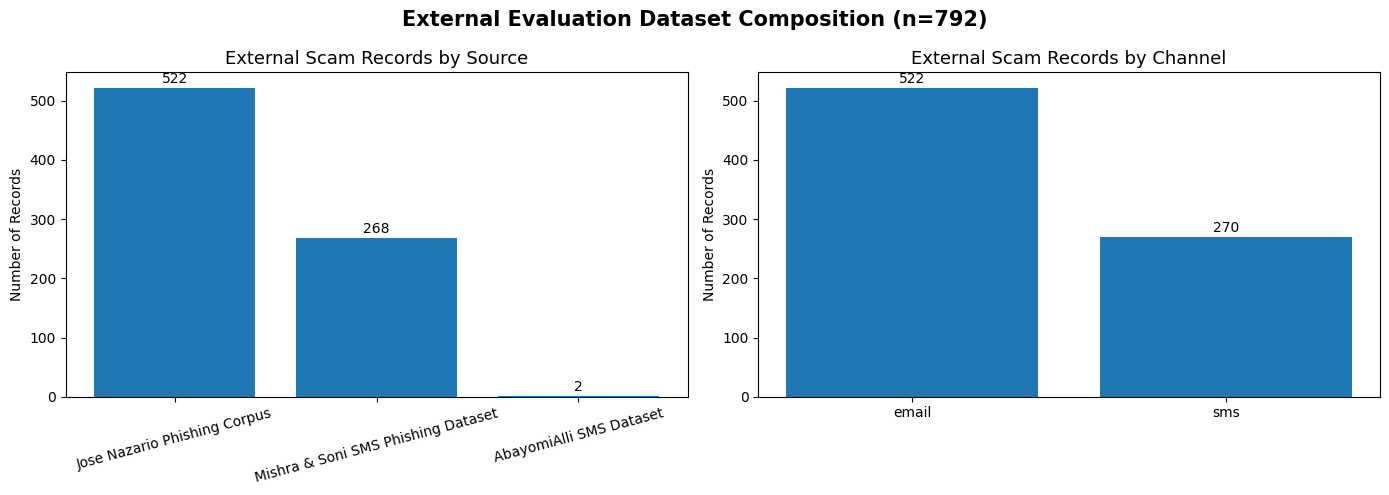

In [28]:
# ============================================================
# CELL 19: EXTERNAL DATASET COMPOSITION VISUALIZATION
# ============================================================

import matplotlib.pyplot as plt
import numpy as np

source_counts = external_scams["source"].value_counts()
channel_counts = external_scams["channel"].value_counts()

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Source distribution
axes[0].bar(
    source_counts.index,
    source_counts.values
)

axes[0].set_title("External Scam Records by Source", fontsize=13)
axes[0].set_ylabel("Number of Records")
axes[0].tick_params(axis="x", rotation=15)

for i, value in enumerate(source_counts.values):
    axes[0].text(i, value + 8, str(value), ha="center")

# Channel distribution
axes[1].bar(
    channel_counts.index,
    channel_counts.values
)

axes[1].set_title("External Scam Records by Channel", fontsize=13)
axes[1].set_ylabel("Number of Records")

for i, value in enumerate(channel_counts.values):
    axes[1].text(i, value + 8, str(value), ha="center")

fig.suptitle(
    "External Evaluation Dataset Composition (n=792)",
    fontsize=15,
    fontweight="bold"
)

plt.tight_layout()
plt.show()

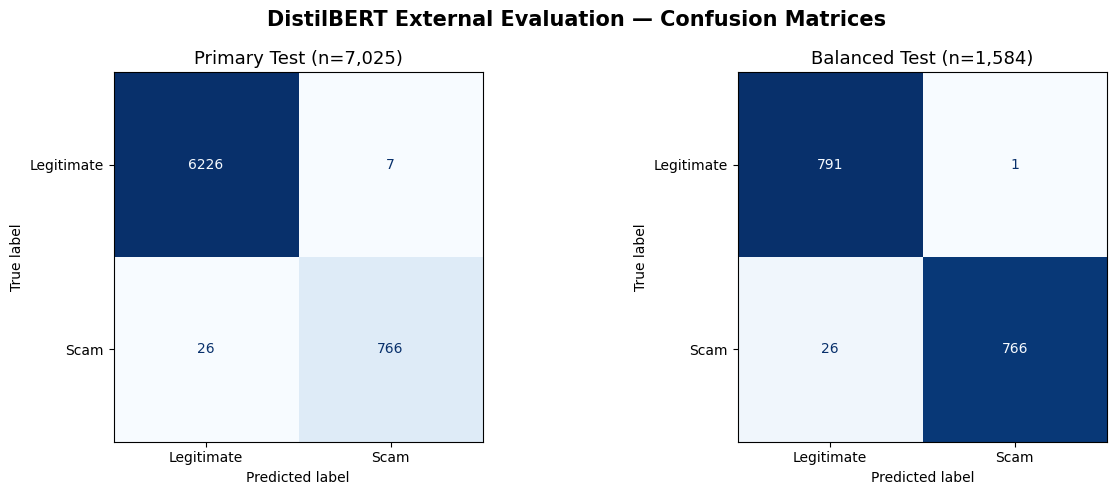

In [29]:
# ============================================================
# CELL 20: CONFUSION MATRIX COMPARISON
# ============================================================

import matplotlib.pyplot as plt
from sklearn.metrics import ConfusionMatrixDisplay

fig, axes = plt.subplots(1, 2, figsize=(13, 5))

ConfusionMatrixDisplay(
    confusion_matrix(
        primary_test_results["label"],
        primary_test_results["predicted_label"],
        labels=[0, 1]
    ),
    display_labels=["Legitimate", "Scam"]
).plot(
    ax=axes[0],
    cmap="Blues",
    colorbar=False,
    values_format="d"
)

axes[0].set_title("Primary Test (n=7,025)", fontsize=13)

ConfusionMatrixDisplay(
    confusion_matrix(
        balanced_test_results["label"],
        balanced_test_results["predicted_label"],
        labels=[0, 1]
    ),
    display_labels=["Legitimate", "Scam"]
).plot(
    ax=axes[1],
    cmap="Blues",
    colorbar=False,
    values_format="d"
)

axes[1].set_title("Balanced Test (n=1,584)", fontsize=13)

fig.suptitle(
    "DistilBERT External Evaluation — Confusion Matrices",
    fontsize=15,
    fontweight="bold"
)

plt.tight_layout()
plt.show()

PERFORMANCE METRICS
               Accuracy  Precision  Recall  F1-score  PR-AUC
Evaluation                                                  
Primary Test     0.9953     0.9909  0.9672    0.9789  0.9968
Balanced Test    0.9830     0.9987  0.9672    0.9827  0.9993


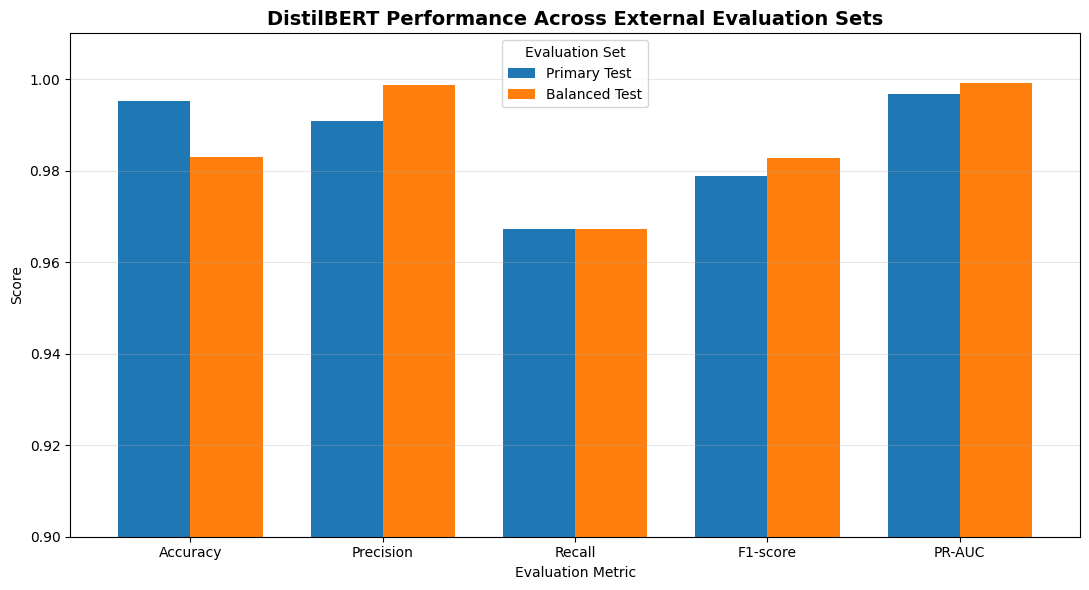

In [30]:
# ============================================================
# CELL 21: PERFORMANCE METRICS COMPARISON
# ============================================================

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    average_precision_score,
    balanced_accuracy_score
)

evaluation_results = {
    "Primary Test": primary_test_results,
    "Balanced Test": balanced_test_results
}

metrics_data = []

for name, results in evaluation_results.items():
    y_true = results["label"]
    y_pred = results["predicted_label"]
    y_prob = results["scam_probability"]

    metrics_data.append({
        "Evaluation": name,
        "Accuracy": accuracy_score(y_true, y_pred),
        "Precision": precision_score(y_true, y_pred),
        "Recall": recall_score(y_true, y_pred),
        "F1-score": f1_score(y_true, y_pred),
        "PR-AUC": average_precision_score(y_true, y_prob)
    })

metrics_df = pd.DataFrame(metrics_data).set_index("Evaluation")

print("PERFORMANCE METRICS")
print(metrics_df.round(4).to_string())

# Plot
ax = metrics_df.T.plot(
    kind="bar",
    figsize=(11, 6),
    width=0.75
)

ax.set_title(
    "DistilBERT Performance Across External Evaluation Sets",
    fontsize=14,
    fontweight="bold"
)
ax.set_ylabel("Score")
ax.set_xlabel("Evaluation Metric")
ax.set_ylim(0.90, 1.01)
ax.tick_params(axis="x", rotation=0)
ax.legend(title="Evaluation Set")
ax.grid(axis="y", alpha=0.3)

plt.tight_layout()
plt.show()

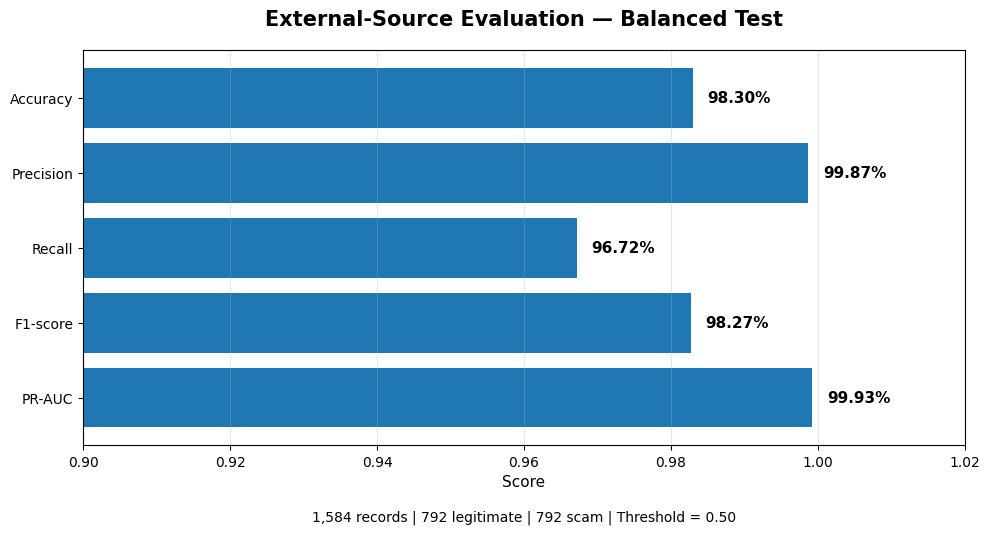

In [31]:
# ============================================================
# CELL 21B: MAIN RESULT — BALANCED TEST PERFORMANCE
# ============================================================

balanced_metrics = {
    "Accuracy": accuracy_score(y_true_bal, y_pred_bal),
    "Precision": precision_score(y_true_bal, y_pred_bal),
    "Recall": recall_score(y_true_bal, y_pred_bal),
    "F1-score": f1_score(y_true_bal, y_pred_bal),
    "PR-AUC": average_precision_score(y_true_bal, y_prob_bal)
}

fig, ax = plt.subplots(figsize=(10, 5.5))

names = list(balanced_metrics.keys())
values = list(balanced_metrics.values())

bars = ax.barh(names, values)

ax.set_xlim(0.90, 1.02)
ax.set_xlabel("Score", fontsize=11)
ax.set_title(
    "External-Source Evaluation — Balanced Test",
    fontsize=15,
    fontweight="bold",
    pad=18
)

ax.invert_yaxis()
ax.grid(axis="x", alpha=0.3)

for bar, value in zip(bars, values):
    ax.text(
        value + 0.002,
        bar.get_y() + bar.get_height() / 2,
        f"{value * 100:.2f}%",
        va="center",
        fontsize=11,
        fontweight="bold"
    )

ax.text(
    0.5, -0.19,
    "1,584 records | 792 legitimate | 792 scam | Threshold = 0.50",
    transform=ax.transAxes,
    ha="center",
    fontsize=10
)

plt.tight_layout()
plt.show()

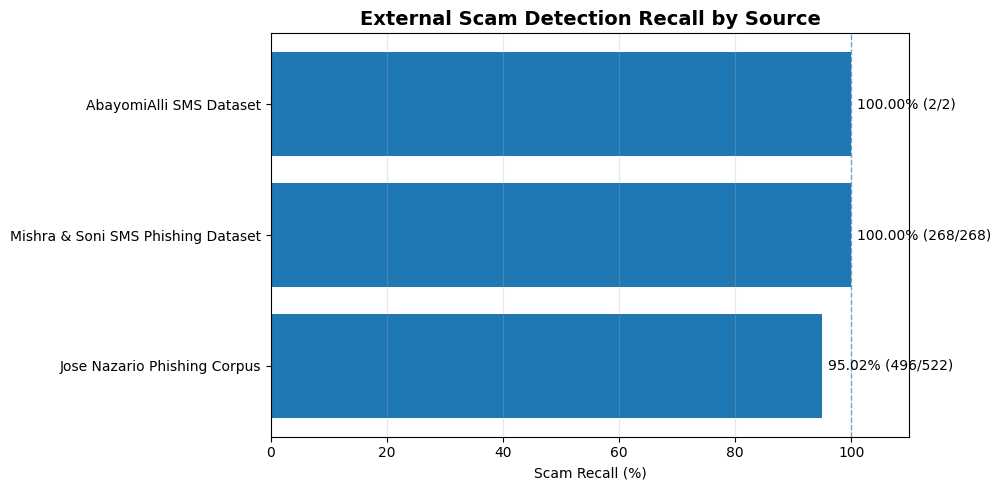

In [32]:
# ============================================================
# CELL 22: SOURCE-WISE EXTERNAL SCAM RECALL
# ============================================================

fig, ax = plt.subplots(figsize=(10, 5))

plot_data = source_summary.sort_values(
    "Scam Recall (%)", ascending=True
)

bars = ax.barh(
    plot_data["Source"],
    plot_data["Scam Recall (%)"]
)

ax.set_xlim(0, 110)
ax.set_xlabel("Scam Recall (%)")
ax.set_title(
    "External Scam Detection Recall by Source",
    fontsize=14,
    fontweight="bold"
)

ax.axvline(
    100,
    linestyle="--",
    linewidth=1,
    alpha=0.6
)

ax.grid(axis="x", alpha=0.3)

for bar, (_, row) in zip(bars, plot_data.iterrows()):
    ax.text(
        row["Scam Recall (%)"] + 1,
        bar.get_y() + bar.get_height() / 2,
        f'{row["Scam Recall (%)"]:.2f}% ({row["Detected"]}/{row["Total Scams"]})',
        va="center",
        fontsize=10
    )

plt.tight_layout()
plt.show()

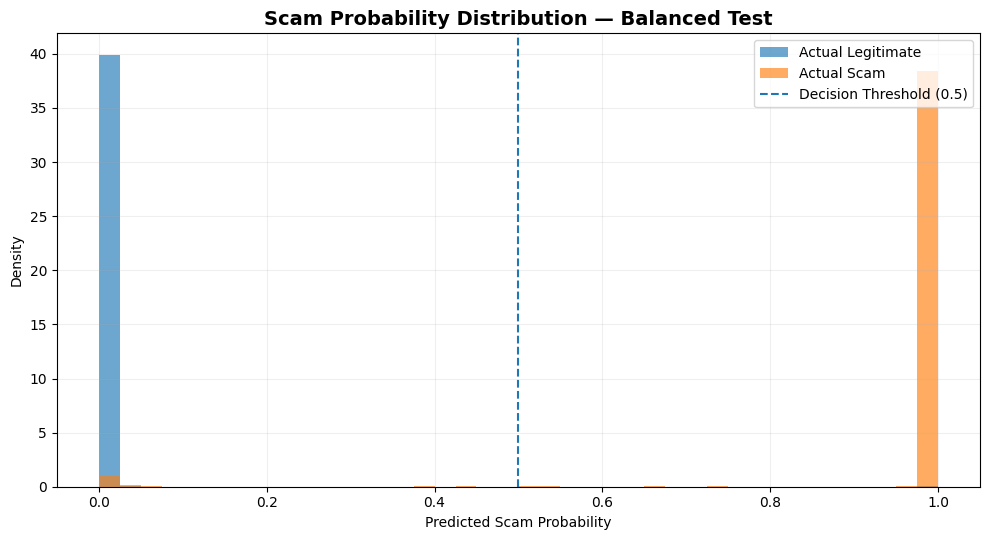

In [33]:
# ============================================================
# CELL 23: SCAM PROBABILITY DISTRIBUTION
# ============================================================

fig, ax = plt.subplots(figsize=(10, 5.5))

legit_probabilities = balanced_test_results.loc[
    balanced_test_results["label"] == LEGITIMATE_LABEL,
    "scam_probability"
]

scam_probabilities = balanced_test_results.loc[
    balanced_test_results["label"] == SCAM_LABEL,
    "scam_probability"
]

ax.hist(
    legit_probabilities,
    bins=40,
    alpha=0.65,
    label="Actual Legitimate",
    density=True
)

ax.hist(
    scam_probabilities,
    bins=40,
    alpha=0.65,
    label="Actual Scam",
    density=True
)

ax.axvline(
    THRESHOLD,
    linestyle="--",
    linewidth=1.5,
    label=f"Decision Threshold ({THRESHOLD})"
)

ax.set_title(
    "Scam Probability Distribution — Balanced Test",
    fontsize=14,
    fontweight="bold"
)
ax.set_xlabel("Predicted Scam Probability")
ax.set_ylabel("Density")
ax.legend()
ax.grid(alpha=0.2)

plt.tight_layout()
plt.show()

In [34]:
# ============================================================
# CELL 24: NOTEBOOK 09 — FINAL EXPERIMENT SUMMARY
# ============================================================

from sklearn.metrics import (
    accuracy_score, precision_score, recall_score,
    f1_score, balanced_accuracy_score,
    average_precision_score, roc_auc_score
)

print("=" * 80)
print("NOTEBOOK 09: EXTERNAL-SOURCE GENERALIZATION EVALUATION")
print("=" * 80)

print("\nEXPERIMENT CONFIGURATION")
print("-" * 80)
print("Model: Original Notebook06 DistilBERT Binary Classifier")
print("Training: No retraining or fine-tuning")
print(f"Maximum sequence length: {MAX_LENGTH}")
print(f"Decision threshold: {THRESHOLD}")
print(f"Inference device: {DEVICE}")

print("\nEXTERNAL DATASET")
print("-" * 80)
print(f"External scam records: {len(external_scams)}")
print(f"Sources: {external_scams['source'].nunique()}")
print(f"Channels: {external_scams['channel'].nunique()}")
print(f"External scam detections: {total_detected}")
print(f"External scam false negatives: {total_scams - total_detected}")
print(f"External scam recall: {total_detected / total_scams:.4f}")

print("\nPRIMARY TEST")
print("-" * 80)

for metric, value in {
    "Accuracy": accuracy_score(
        primary_test_results["label"],
        primary_test_results["predicted_label"]
    ),
    "Scam Precision": precision_score(
        primary_test_results["label"],
        primary_test_results["predicted_label"]
    ),
    "Scam Recall": recall_score(
        primary_test_results["label"],
        primary_test_results["predicted_label"]
    ),
    "Scam F1": f1_score(
        primary_test_results["label"],
        primary_test_results["predicted_label"]
    ),
    "Balanced Accuracy": balanced_accuracy_score(
        primary_test_results["label"],
        primary_test_results["predicted_label"]
    ),
    "PR-AUC": average_precision_score(
        primary_test_results["label"],
        primary_test_results["scam_probability"]
    ),
    "ROC-AUC": roc_auc_score(
        primary_test_results["label"],
        primary_test_results["scam_probability"]
    )
}.items():
    print(f"{metric:<22}: {value:.4f}")

print("\nBALANCED TEST")
print("-" * 80)

for metric, value in {
    "Accuracy": accuracy_score(
        balanced_test_results["label"],
        balanced_test_results["predicted_label"]
    ),
    "Scam Precision": precision_score(
        balanced_test_results["label"],
        balanced_test_results["predicted_label"]
    ),
    "Scam Recall": recall_score(
        balanced_test_results["label"],
        balanced_test_results["predicted_label"]
    ),
    "Scam F1": f1_score(
        balanced_test_results["label"],
        balanced_test_results["predicted_label"]
    ),
    "Balanced Accuracy": balanced_accuracy_score(
        balanced_test_results["label"],
        balanced_test_results["predicted_label"]
    ),
    "PR-AUC": average_precision_score(
        balanced_test_results["label"],
        balanced_test_results["scam_probability"]
    ),
    "ROC-AUC": roc_auc_score(
        balanced_test_results["label"],
        balanced_test_results["scam_probability"]
    )
}.items():
    print(f"{metric:<22}: {value:.4f}")

print("\nKEY LIMITATIONS")
print("-" * 80)
print("1. External scams are combined with legitimate controls from the")
print("   original held-out test partition.")
print("2. Source and channel distributions are confounded.")
print("3. AbayomiAlli contributes only two verified scam records.")
print("4. Primary and balanced tests reuse the same external scam records.")
print("5. Results represent the curated evaluation collection, not all")
print("   real-world financial scam populations.")

print("\n" + "=" * 80)
print("NOTEBOOK 09 EXPERIMENT COMPLETED")
print("=" * 80)

NOTEBOOK 09: EXTERNAL-SOURCE GENERALIZATION EVALUATION

EXPERIMENT CONFIGURATION
--------------------------------------------------------------------------------
Model: Original Notebook06 DistilBERT Binary Classifier
Training: No retraining or fine-tuning
Maximum sequence length: 512
Decision threshold: 0.5
Inference device: cuda

EXTERNAL DATASET
--------------------------------------------------------------------------------
External scam records: 792
Sources: 3
Channels: 2
External scam detections: 766
External scam false negatives: 26
External scam recall: 0.9672

PRIMARY TEST
--------------------------------------------------------------------------------
Accuracy              : 0.9953
Scam Precision        : 0.9909
Scam Recall           : 0.9672
Scam F1               : 0.9789
Balanced Accuracy     : 0.9830
PR-AUC                : 0.9968
ROC-AUC               : 0.9994

BALANCED TEST
--------------------------------------------------------------------------------
Accuracy         

In [35]:
# ============================================================
# CELL 25: SAVE EXTERNAL EVALUATION PREDICTIONS
# ============================================================

OUTPUT_DIR = PROJECT_DIR / "outputs" / "external_evaluation"
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

prediction_files = {
    "external_scam_predictions.csv": external_scam_results,
    "primary_test_predictions.csv": primary_test_results,
    "balanced_test_predictions.csv": balanced_test_results
}

for filename, df in prediction_files.items():
    output_path = OUTPUT_DIR / filename
    df.to_csv(output_path, index=False)

    print(f"Saved: {output_path.name} | {len(df)} records")

print("\nAll prediction files saved successfully.")
print(f"Output directory: {OUTPUT_DIR}")

Saved: external_scam_predictions.csv | 792 records
Saved: primary_test_predictions.csv | 7025 records
Saved: balanced_test_predictions.csv | 1584 records

All prediction files saved successfully.
Output directory: /content/drive/MyDrive/financial-scam-analysis/outputs/external_evaluation
